# Previsão de Cancelamento de Clientes (Churn) com Rede Neural MLP

## 1. Contexto do problema

O dataset **Telco Customer Churn** foi disponibilizado pela IBM como amostra de uma operadora de telecomunicações fictícia e é publicado no Kaggle em [blastchar/telco-customer-churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Cada linha representa um cliente, com dados demográficos, serviços contratados, informações de conta e a indicação de cancelamento no último mês.

Em telecom, adquirir um cliente novo custa bem mais do que reter um existente. Prever quem tem alta probabilidade de cancelar permite que a área de retenção atue antes da perda, direcionando ofertas e contato apenas para quem realmente está em risco.

O problema é de **classificação binária**: o alvo `Churn` indica se o cliente cancelou (`cancela`) ou permaneceu (`permanece`).

### Dicionário de dados

| Coluna | Tipo | Significado |
|---|---|---|
| `customerID` | texto | Identificador do cliente (descartado na modelagem) |
| `gender` | categórica | Gênero do cliente (`Male`, `Female`) |
| `SeniorCitizen` | binária (0/1) | Indica se o cliente tem 65 anos ou mais |
| `Partner` | categórica | Possui cônjuge/companheiro(a) |
| `Dependents` | categórica | Possui dependentes |
| `tenure` | numérica (int) | Meses de permanência na operadora |
| `PhoneService` | categórica | Possui linha telefônica |
| `MultipleLines` | categórica | Possui múltiplas linhas |
| `InternetService` | categórica | Tipo de internet (`DSL`, `Fiber optic`, `No`) |
| `OnlineSecurity` | categórica | Contratou segurança online |
| `OnlineBackup` | categórica | Contratou backup online |
| `DeviceProtection` | categórica | Contratou proteção de aparelho |
| `TechSupport` | categórica | Contratou suporte técnico |
| `StreamingTV` | categórica | Contratou streaming de TV |
| `StreamingMovies` | categórica | Contratou streaming de filmes |
| `Contract` | categórica | Tipo de contrato (`Month-to-month`, `One year`, `Two year`) |
| `PaperlessBilling` | categórica | Fatura digital |
| `PaymentMethod` | categórica | Forma de pagamento |
| `MonthlyCharges` | numérica (float) | Valor cobrado mensalmente |
| `TotalCharges` | numérica (float) | Valor total cobrado durante a permanência |
| `Churn` | categórica (alvo) | Cliente cancelou no último mês |

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    matthews_corrcoef,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEED = 77

## 2. Análise exploratória

In [2]:
df = pd.read_csv(RAIZ / "data" / "dataset.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

O `info()` não aponta nulos, mas `TotalCharges` foi lido como texto, o que indica valores não numéricos escondidos na coluna.

In [4]:
em_branco = df["TotalCharges"].str.strip() == ""
print("Nulos por coluna:", df.isna().sum().sum())
print("TotalCharges em branco:", em_branco.sum())
df.loc[em_branco, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Nulos por coluna: 0
TotalCharges em branco: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


Os 11 registros sem `TotalCharges` têm `tenure = 0`: são clientes que acabaram de entrar e ainda não receberam a primeira fatura. O valor correto para eles é zero, então a coluna é convertida para numérica preenchendo esses casos com 0, sem descartar linhas.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)
df["Churn"] = df["Churn"].map({"Yes": "cancela", "No": "permanece"})
df = df.drop(columns="customerID")
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


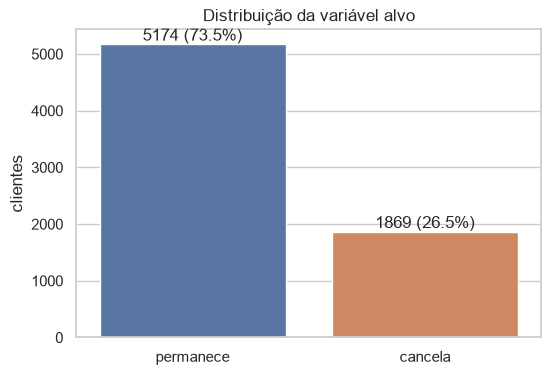

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#4C72B0", "#DD8452"], ax=ax)
for barra in ax.containers:
    ax.bar_label(barra, fmt=lambda v: f"{v:.0f} ({v / len(df):.1%})")
ax.set_title("Distribuição da variável alvo")
ax.set_xlabel("")
ax.set_ylabel("clientes")
plt.show()

A base é desbalanceada: cerca de 73% dos clientes permanecem e 27% cancelam. Por isso a divisão treino/teste é estratificada e, além da acurácia, o modelo é avaliado pelo **MCC (Matthews Correlation Coefficient)**, que não é inflado pela classe majoritária.

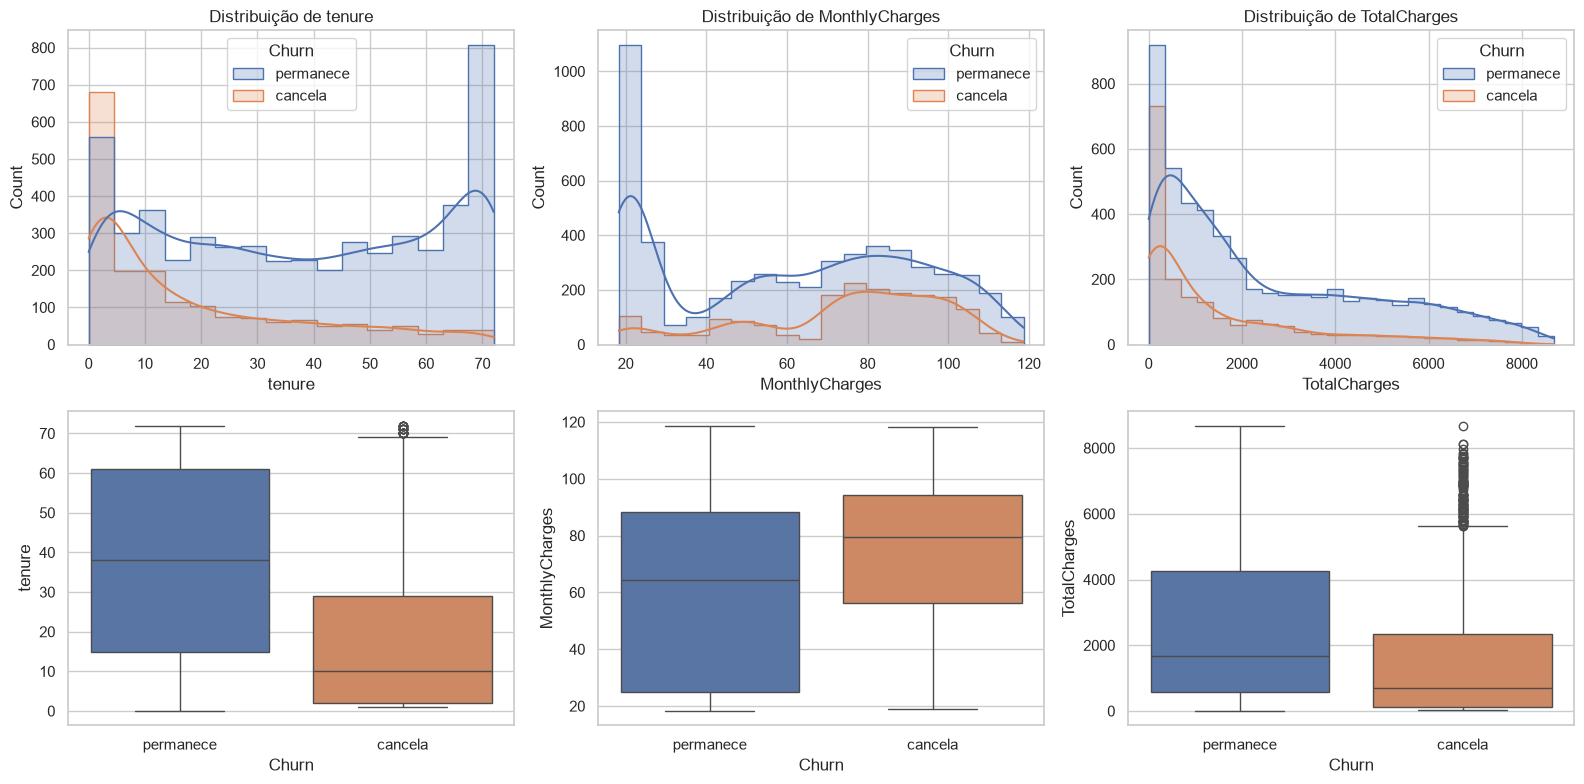

In [7]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, eixos = plt.subplots(2, 3, figsize=(16, 8))
for i, coluna in enumerate(numericas):
    sns.histplot(data=df, x=coluna, hue="Churn", kde=True, element="step", ax=eixos[0, i])
    sns.boxplot(data=df, x="Churn", y=coluna, hue="Churn", ax=eixos[1, i])
    eixos[0, i].set_title(f"Distribuição de {coluna}")
plt.tight_layout()
plt.show()

- **`tenure`**: quem cancela está concentrado nos primeiros meses. Clientes antigos raramente saem.
- **`MonthlyCharges`**: mensalidades mais altas aparecem com mais frequência entre os que cancelam.
- **`TotalCharges`**: é consequência de `tenure × MonthlyCharges`, por isso também é menor entre quem cancela.

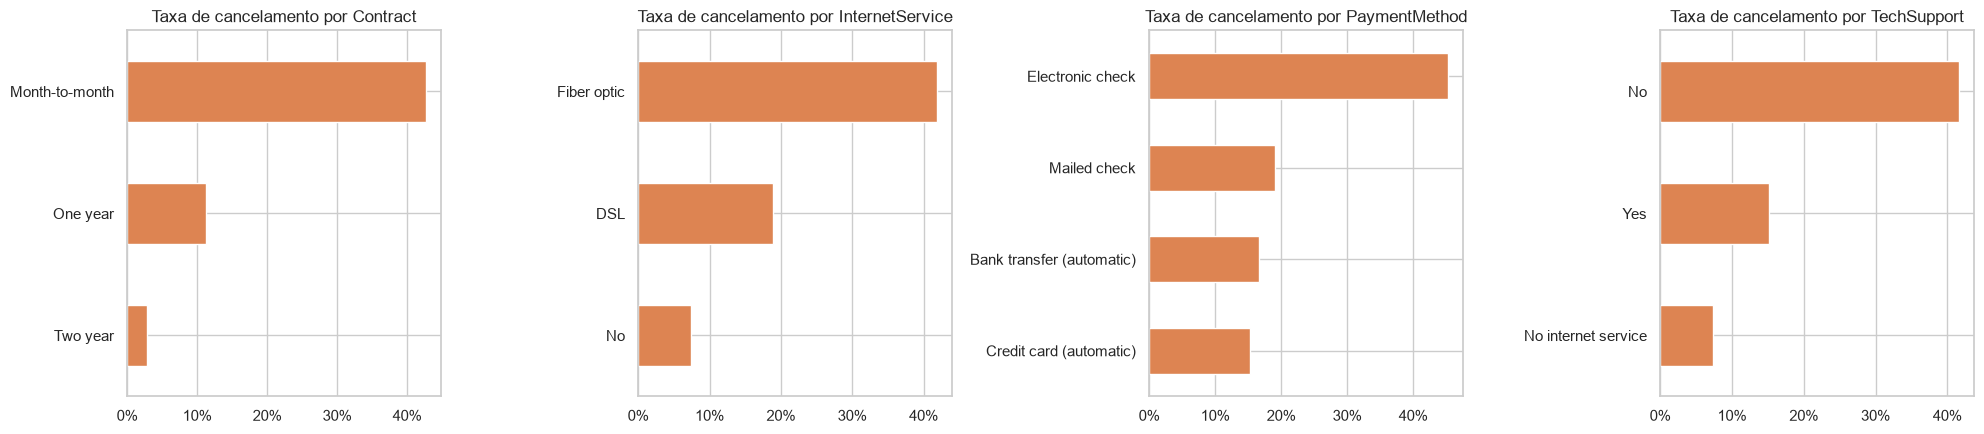

In [8]:
criticas = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]

fig, eixos = plt.subplots(1, 4, figsize=(20, 4.5))
for eixo, coluna in zip(eixos, criticas):
    taxa = df.groupby(coluna)["Churn"].apply(lambda s: (s == "cancela").mean()).sort_values()
    taxa.plot.barh(ax=eixo, color="#DD8452")
    eixo.set_title(f"Taxa de cancelamento por {coluna}")
    eixo.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    eixo.set_ylabel("")
plt.tight_layout()
plt.show()

Contratos mensais, internet de fibra, pagamento por boleto eletrônico (`Electronic check`) e ausência de suporte técnico concentram as maiores taxas de cancelamento. Essas variáveis categóricas carregam sinal relevante e entram no modelo via One-Hot Encoding.

## 3. Construção do pipeline

In [9]:
categoricas = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
]

X = df[numericas + categoricas]
y = df["Churn"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"Treino: {X_treino.shape} | Teste: {X_teste.shape}")

Treino: (5634, 19) | Teste: (1409, 19)


`SeniorCitizen` já vem como 0/1, mas é um indicador e não uma grandeza, então é tratado como categórico junto com as demais colunas de texto.

Sobre a rede:
- três camadas ocultas `(128, 64, 32)` com ReLU;
- `learning_rate_init=0.001` com otimizador Adam;
- `alpha=0.001` de regularização L2;
- `early_stopping` reservando 10% do treino para validação, o que interrompe o treino quando a perda de validação para de melhorar e evita overfitting.

In [10]:
preprocessador = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
])

rede = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    alpha=0.001,
    batch_size=64,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=SEED,
)

pipeline = Pipeline([("preprocessamento", preprocessador), ("mlp", rede)])
pipeline.fit(X_treino, y_treino)
print(f"Épocas treinadas: {rede.n_iter_}")
print(f"Melhor acurácia na validação interna: {rede.best_validation_score_:.4f}")

Épocas treinadas: 26
Melhor acurácia na validação interna: 0.8138


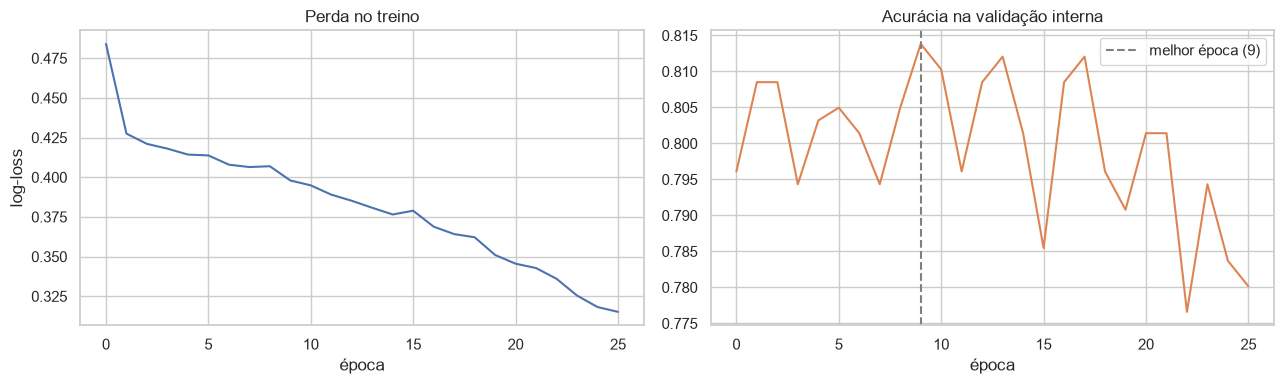

In [11]:
melhor_epoca = int(np.argmax(rede.validation_scores_))

fig, (ax_perda, ax_val) = plt.subplots(1, 2, figsize=(13, 4))
ax_perda.plot(rede.loss_curve_)
ax_perda.set_title("Perda no treino")
ax_perda.set_ylabel("log-loss")
ax_val.plot(rede.validation_scores_, color="#DD8452")
ax_val.axvline(melhor_epoca, color="gray", linestyle="--", label=f"melhor época ({melhor_epoca})")
ax_val.set_title("Acurácia na validação interna")
ax_val.legend()
for eixo in (ax_perda, ax_val):
    eixo.set_xlabel("época")
plt.tight_layout()
plt.show()

A perda de treino cai de forma contínua, mas a acurácia de validação atinge o pico cedo e passa a oscilar: a partir daí a rede começa a decorar o treino. O `early_stopping` interrompe o processo após 15 épocas sem melhora e restaura os pesos da melhor época, que são os usados no modelo final.

## 4. Avaliação do modelo

In [12]:
y_pred = pipeline.predict(X_teste)

print(f"Acurácia: {accuracy_score(y_teste, y_pred):.4f}")
print(f"MCC:      {matthews_corrcoef(y_teste, y_pred):.4f}")
print()
print(classification_report(y_teste, y_pred, digits=4))

Acurácia: 0.8155
MCC:      0.4982

              precision    recall  f1-score   support

     cancela     0.6939    0.5455    0.6108       374
   permanece     0.8475    0.9130    0.8791      1035

    accuracy                         0.8155      1409
   macro avg     0.7707    0.7292    0.7449      1409
weighted avg     0.8067    0.8155    0.8079      1409



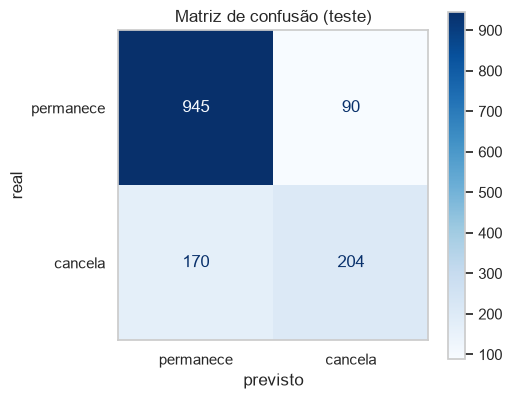

In [13]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, y_pred, labels=["permanece", "cancela"], cmap="Blues", ax=ax
)
ax.set_title("Matriz de confusão (teste)")
ax.set_xlabel("previsto")
ax.set_ylabel("real")
ax.grid(False)
plt.show()

**Leitura dos resultados.**

A acurácia sozinha não diz muito aqui: um modelo que respondesse sempre `permanece` acertaria cerca de 73%. O MCC é a métrica mais honesta para essa base, porque considera as quatro células da matriz e vai de -1 a 1, com 0 equivalente a chute.

Na matriz de confusão:
- **Falsos negativos** (cancelou, mas o modelo previu `permanece`) são o erro mais caro para o negócio, porque o cliente sai sem nenhuma ação de retenção.
- **Falsos positivos** (permaneceu, mas o modelo previu `cancela`) geram custo de uma oferta desnecessária, que normalmente é bem menor.

Se a área de negócio quiser priorizar o recall de `cancela`, a API já devolve a probabilidade, o que permite ajustar o limiar de decisão sem retreinar a rede.

## 5. Exportação do modelo

In [14]:
destino = RAIZ / "models" / "pipeline_rede_neural.joblib"
destino.parent.mkdir(exist_ok=True)
joblib.dump(pipeline, destino)
print(f"{destino.relative_to(RAIZ)} ({destino.stat().st_size / 1024:.0f} KB)")

models\pipeline_rede_neural.joblib (399 KB)


In [15]:
carregado = joblib.load(destino)
amostra = X_teste.head(3)
pd.DataFrame({
    "real": y_teste.head(3).values,
    "previsto": carregado.predict(amostra),
    "confianca": carregado.predict_proba(amostra).max(axis=1).round(4),
}, index=amostra.index)

,real,previsto,confianca
4212,cancela,cancela,0.7589
5001,cancela,permanece,0.8696
6241,cancela,cancela,0.5812


O pipeline salvo carrega o `StandardScaler` com médias e desvios do treino, o `OneHotEncoder` com as categorias conhecidas e a rede treinada. A API recebe os dados brutos do cliente e aplica exatamente as mesmas transformações usadas aqui.